# E5 · Detect the springs (step 1b)
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

The gates are no longer given. Can the learned body and spring maps find which springs are live?

**Where we're at.** Step 1b: the springs are no longer given.

**Where the system is after the last experiments.** With the gates known, the model predicts every configuration tested so far (E2 to E4).

**Where we want it.** The gates recovered from data, with no spurious springs.

**How this set moves it.** Solves for all 10 candidate springs of 5 bodies, by least squares with and without non-negativity, from one or three trajectories, across noise levels and window lengths.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e5")
world = config.world_from(cfg)
p = cfg["e5"]

In [2]:
F.ledger("e5")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | ring | how the springs are wired |
| `n` | 5 | number of bodies |
| `kappas` | [1.0, 16.0] | spring stiffnesses swept (1/s²) |
| `windows` | [10, 50, 200] | window lengths (steps) |
| `noise` | [0.0, 0.01, 0.05] | measurement noise, fraction of the swing |
| `trajectories` | [1, 3] | trajectories per run |
| `methods` | ['lstsq', 'nnls'] | detection methods |
| `trials` | 40 | trials per condition and seed |
| `amplitude` | 0.1 | starting swing size (rad) |
| `p_on` | 0.5 | chance each spring is live |

## The question

With $K$ and $M$ known, the step is linear in the gates. Every pair $(a, b)$ is a candidate spring:

$$\underbrace{x_v(t+1) - K x_v(t)}_{\text{residual of body } v} \;=\; \sum_{(a,b)} g_{ab}\,G_{ab}, \qquad G_{ab} = \begin{cases} -M\,(x_b - x_a) & \text{at } b\\ +M\,(x_b - x_a) & \text{at } a\end{cases}$$

**Prediction.** Clean data give the gates exactly, with one exception: when several identical pendulums hang free, they all swing at $\omega_0$, and from one trajectory some combinations of springs among them change no prediction. Non-negativity ($g\ge 0$) or a second trajectory removes that blind spot.
**Pass if** the AUROC is at least 0.95 at 1% noise and no never-wired pair scores above 0.5.

In [3]:
runs = F.ensure_results("e5")

e5: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:56+00:00)


## The world: a ring of 5, and 10 candidate springs

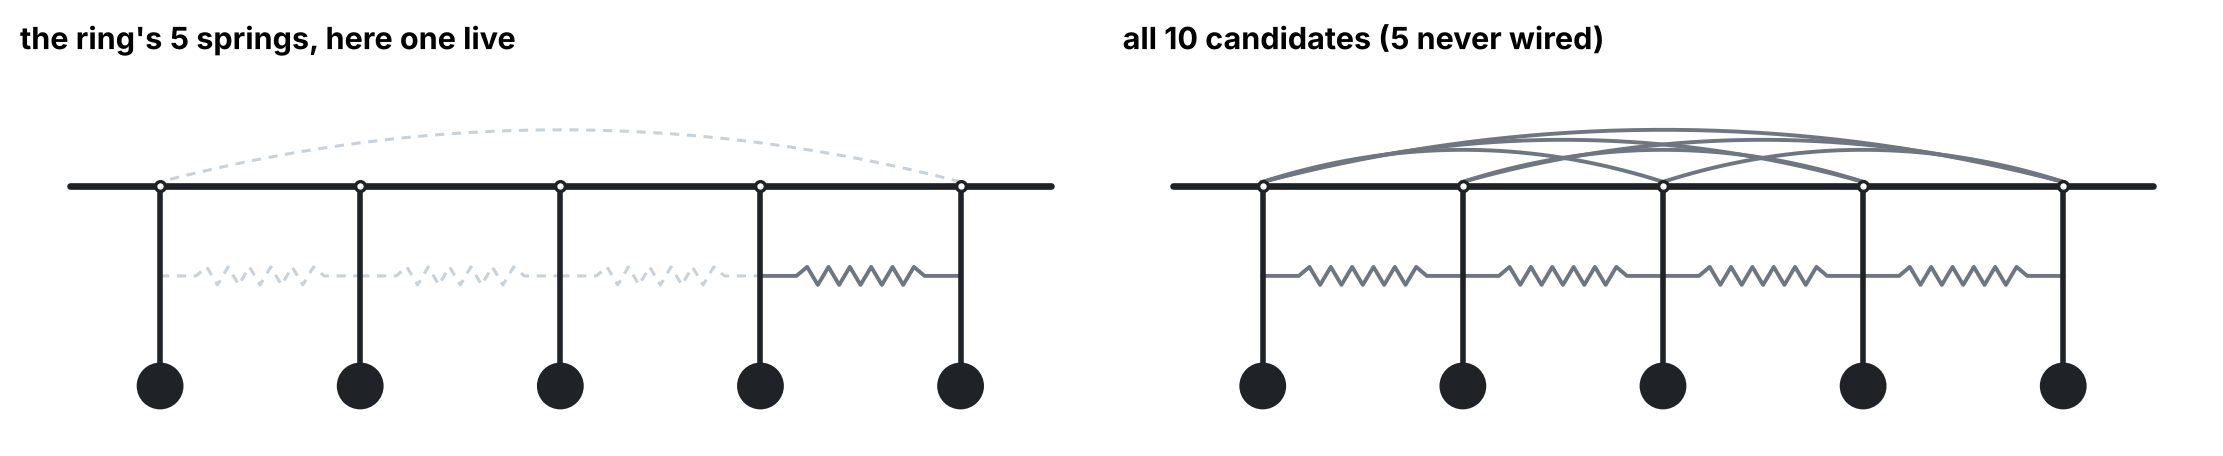

In [4]:
ring, pairs = graphs.ring(5), graphs.complete(5)
g_one = np.array([0, 0, 0, 1, 0.0])
F.schematics([("the ring's 5 springs, here one live", 5, ring, g_one),
              ("all 10 candidates (5 never wired)", 5, pairs, None)], cols=2);

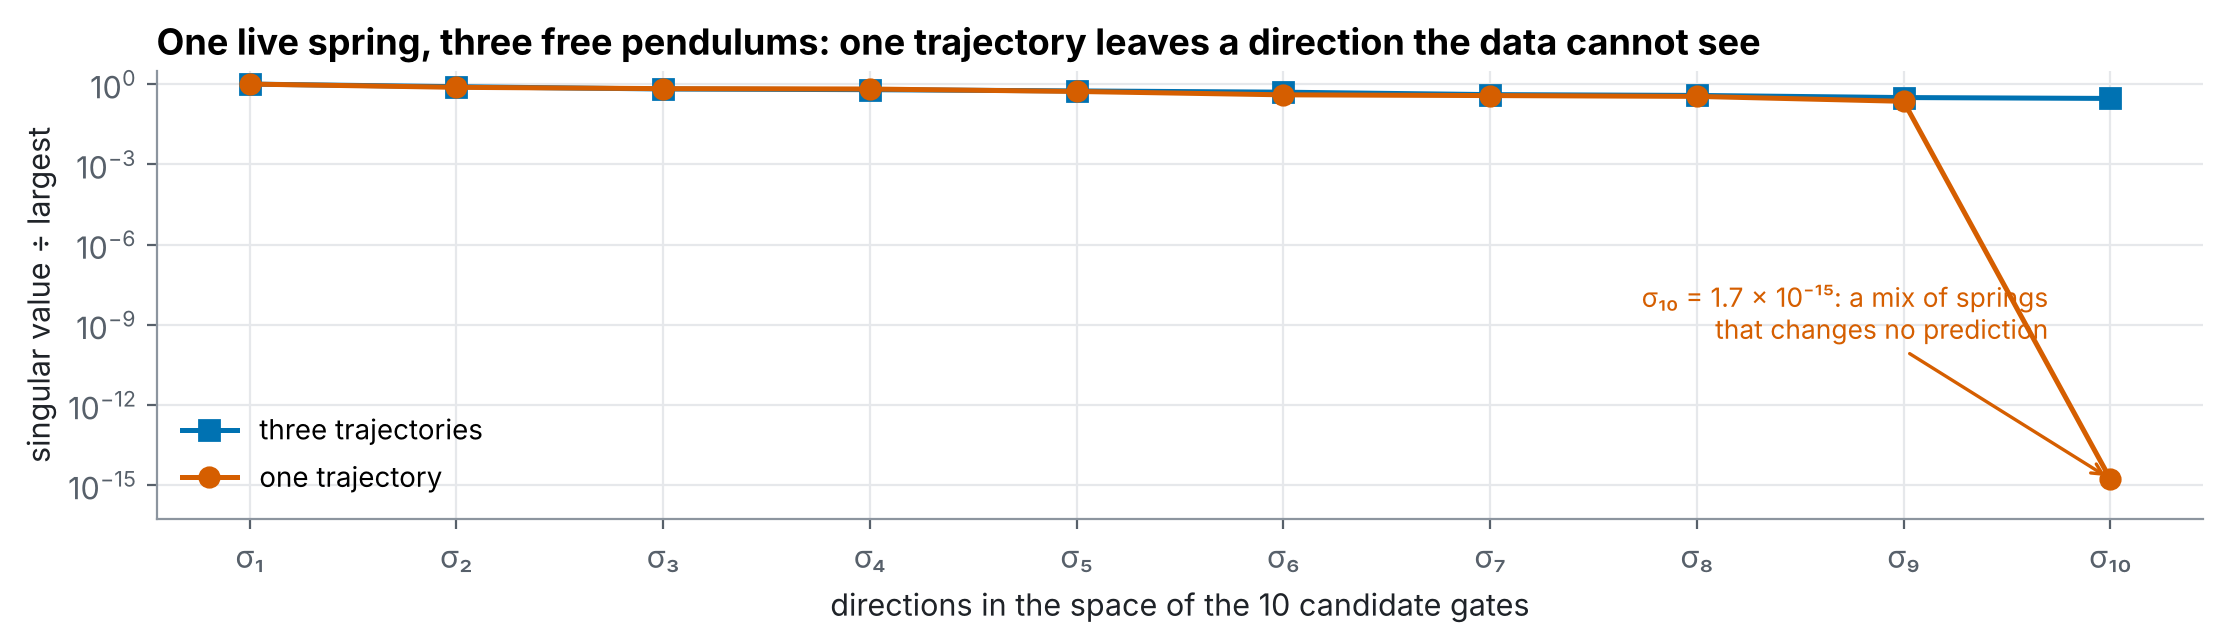

In [5]:
F.e5_blind_spot(runs[0]);

## Nominal vs actual: rollouts with the detected gates

The blind-spot case: one live spring, 50 steps of one noisy trajectory. Each nominal world runs on the gates its method detected. Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time.

In [6]:
a = runs[0]["arrays"]
tol = 0.01 * p["amplitude"]
for mt, label in (("lstsq", "plain least squares"), ("nnls", "non-negative least squares")):
    g = a[f"g_{mt}"]
    keep = [k for k in range(len(pairs)) if a["truth"][k] > 0.5 or abs(g[k]) > 0.1]
    display(viz.player(a["theta_act"], a[f"theta_nom_{mt}"], [pairs[k] for k in keep], a["truth"][keep], dt=world.dt,
                       tol=tol, nominal_gates=(np.abs(g[keep]) > 0.1).astype(float),
                       title=f"Gates from {label}",
                       subtitle="Free-running for 10 s on the detected gates (all of them, at their estimated strengths). "
                                "Blue dashed springs: gates above 0.1 that the actual world does not have."))

In [7]:
g = a["g_nnls"]
spur = [k for k in range(len(pairs)) if a["truth"][k] < 0.5]
k = max(spur, key=lambda j: g[j])
u, v = pairs[k]
end = np.abs(a["theta_nom_nnls"][-1] - a["theta_act"][-1])
rest = max(end[i] for i in range(5) if i not in (u, v))
F.say(f"Even non-negative least squares leaves a spring of strength {viz.fmt(g[k])} between bodies {u + 1} and {v + 1}. By "
      f"10 s they deviate by {viz.fmt(end[u])} and {viz.fmt(end[v])} rad, against at most {viz.fmt(rest)} for the others. "
      "Pendulums with nothing else attached all swing at ω₀, so they are in resonance with each other: a weak spring "
      "between two of them trades swing back and forth steadily instead of averaging out.")

> **Finding.** Even non-negative least squares leaves a spring of strength 0.00918 between bodies 1 and 2. By 10 s they deviate by 0.0041 and 0.0041 rad, against at most 0.0011 for the others. Pendulums with nothing else attached all swing at ω₀, so they are in resonance with each other: a weak spring between two of them trades swing back and forth steadily instead of averaging out.

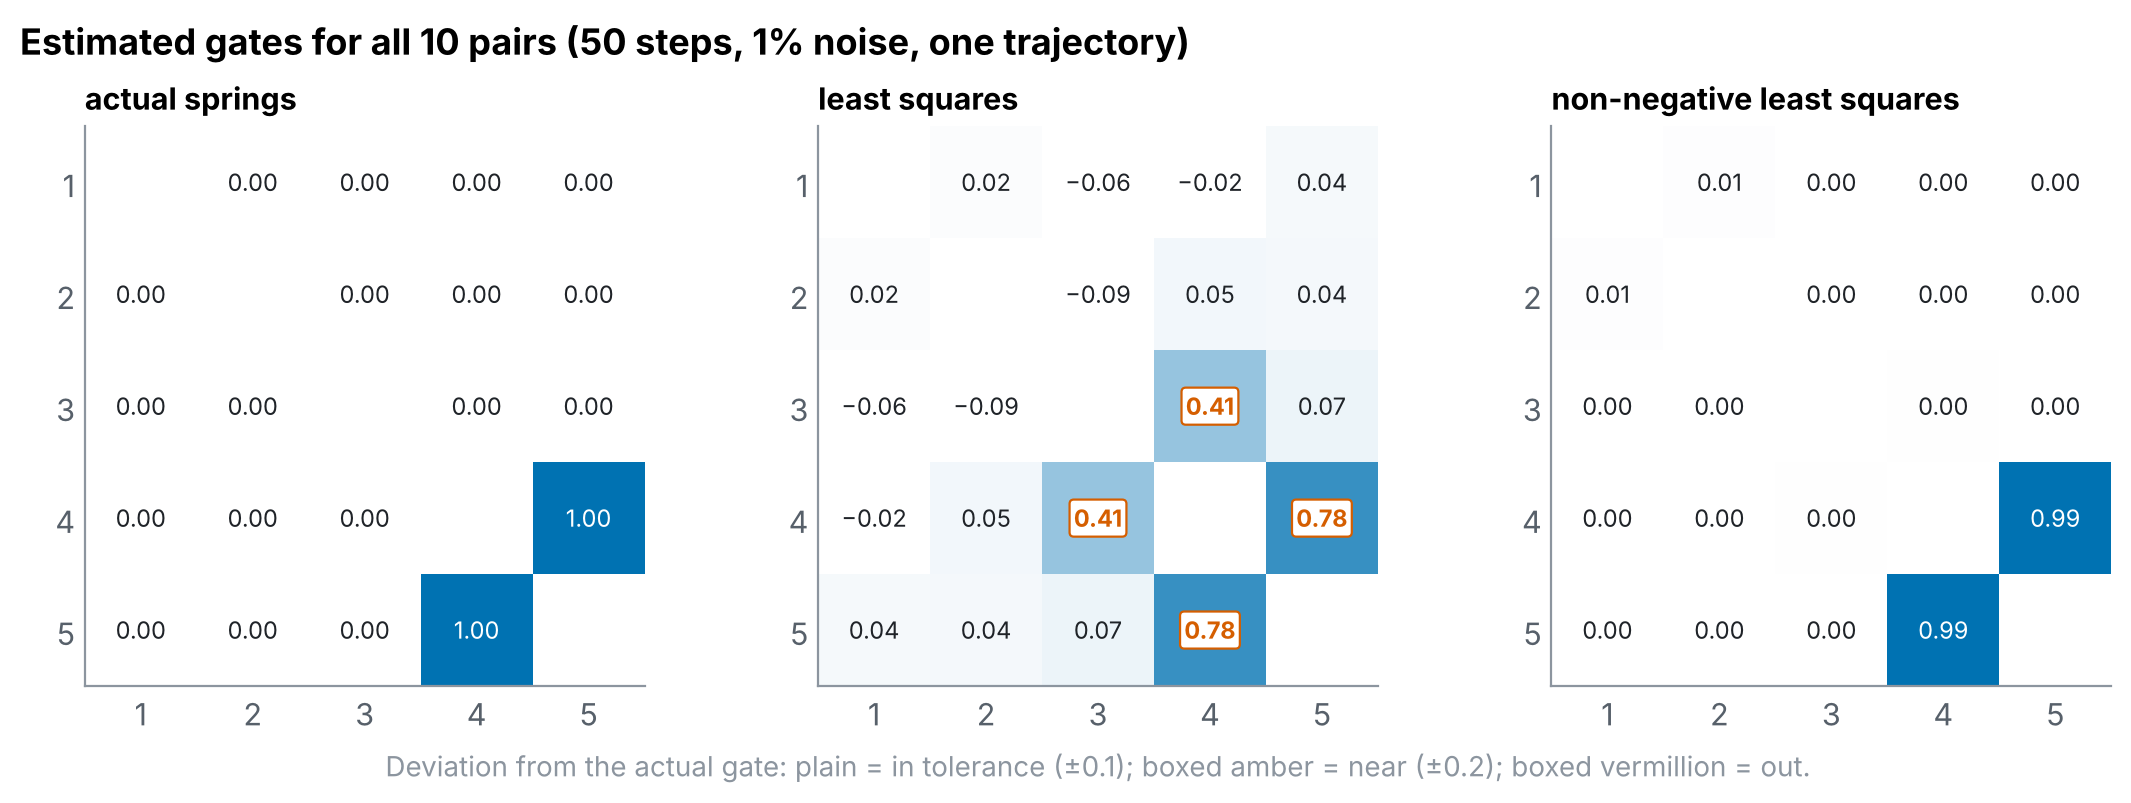

In [8]:
F.e5_matrices(runs[0]);

## Detection across windows, noise and trajectories

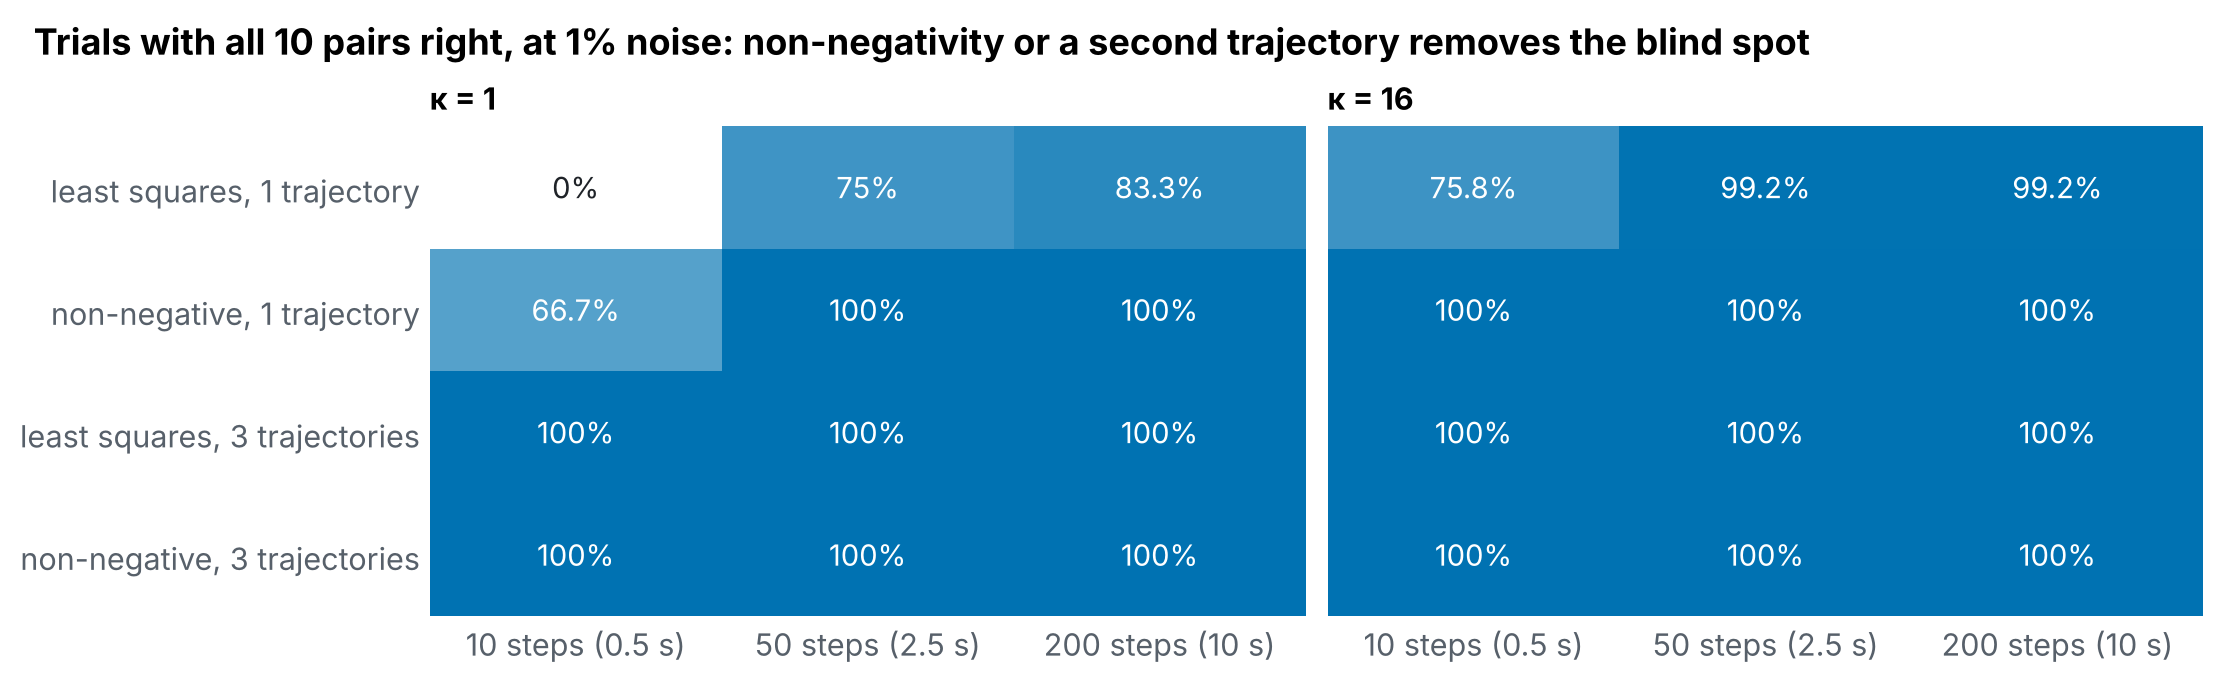

In [9]:
F.e5_exact(runs, dt=world.dt);

In [10]:
rows = [row for r in runs for row in r["metrics"]["rows"]]
pick = lambda **kw: [row for row in rows if all(row[k] == v for k, v in kw.items())]
sel = lambda mt, k: pick(kappa=1.0, window=50, noise=0.01, method=mt, trajectories=k)
F.say(f"At κ = 1, 1% noise and 50 steps, plain least squares on one trajectory is right on all 10 pairs in "
      f"{viz.pct(np.mean([r['exact'] for r in sel('lstsq', 1)]))} of trials, with spurious gates up to "
      f"{viz.fmt(max(r['max_spurious'] for r in sel('lstsq', 1)))}. Non-negativity raises that to "
      f"{viz.pct(np.mean([r['exact'] for r in sel('nnls', 1)]))}, and three trajectories to "
      f"{viz.pct(np.mean([r['exact'] for r in sel('lstsq', 3)]))}. Stiffer springs (κ = 16) are easier to detect: the "
      "spring's effect per step grows with κΔt.")

> **Finding.** At κ = 1, 1% noise and 50 steps, plain least squares on one trajectory is right on all 10 pairs in 75% of trials, with spurious gates up to 6.42. Non-negativity raises that to 100%, and three trajectories to 100%. Stiffer springs (κ = 16) are easier to detect: the spring's effect per step grows with κΔt.

## Inspection report

In [11]:
rep = []
for mt, k in (("lstsq", 1), ("nnls", 1), ("lstsq", 3), ("nnls", 3)):
    s = sel(mt, k)
    au = float(np.mean([r["auroc"] for r in s]))
    sp = float(max(r["max_spurious"] for r in s))
    name = f"{'least squares' if mt == 'lstsq' else 'non-negative'}, {k} traj."
    rep += [{"characteristic": f"{name}: AUROC", "nominal": au, "status": "in" if au >= 0.95 else "out", "tolerance": "≥ 0.95"},
            {"characteristic": f"{name}: largest never-wired gate", "nominal": sp, "status": "in" if sp <= 0.5 else "out",
             "tolerance": "≤ 0.5"}]
viz.inspection_report(rep, title="κ = 1, 1% noise, 50 steps, across seeds")

**κ = 1, 1% noise, 50 steps, across seeds**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| least squares, 1 traj.: AUROC | 0.9389 | — | — | ≥ 0.95 | ✗ **out** |
| least squares, 1 traj.: largest never-wired gate | 6.418 | — | — | ≤ 0.5 | ✗ **out** |
| non-negative, 1 traj.: AUROC | 1 | — | — | ≥ 0.95 | ✓ **in** |
| non-negative, 1 traj.: largest never-wired gate | 0.2574 | — | — | ≤ 0.5 | ✓ **in** |
| least squares, 3 traj.: AUROC | 1 | — | — | ≥ 0.95 | ✓ **in** |
| least squares, 3 traj.: largest never-wired gate | 0.04723 | — | — | ≤ 0.5 | ✓ **in** |
| non-negative, 3 traj.: AUROC | 1 | — | — | ≥ 0.95 | ✓ **in** |
| non-negative, 3 traj.: largest never-wired gate | 0.02532 | — | — | ≤ 0.5 | ✓ **in** |

## Log

In [12]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:56+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:28:57+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:28:58+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |